

```
# This is formatted as code
```

# Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
sns.set()


# Preprocessing

## Import the data & Preview The Data

In [ ]:
raw_data = pd.read_csv('https://docs.google.com/spreadsheets/d/e/2PACX-1vSIpExX-i5xnUPtSIZxENOHc_sQ0-KbKd0EfNaYE3fMEZn9YCD34OLxu41BCrUIfyD_C2KoNcYUKk6Y/pub?gid=135066483&single=true&output=csv')
print('Data Shape =',raw_data.shape)
raw_data         ### Preview of the Dataset

Data Shape = (2000, 11)


,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender,is_fit
0,56,152,65,69.6,117.0,NaN,2.37,3.97,no,F,1
1,69,186,95,60.8,114.8,7.5,8.77,3.19,0,F,1
2,46,192,103,61.4,116.4,NaN,8.20,2.03,0,F,0
3,32,189,83,60.2,130.1,7.0,6.18,3.68,0,M,1
4,60,175,99,58.1,115.8,8.0,9.95,4.83,yes,F,1
...,...,...,...,...,...,...,...,...,...,...,...
1995,52,173,98,60.7,106.1,NaN,1.54,3.25,1,M,1
1996,61,186,74,51.4,123.8,9.4,8.63,3.15,no,M,1
1997,77,198,89,76.7,103.6,8.3,1.98,3.36,yes,M,0
1998,62,190,63,80.7,115.9,6.7,9.21,2.39,1,F,0


## Breakdown The Dataset


In [ ]:
raw_data.describe(include='all')

,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender,is_fit
count,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,1840.000000,2000.000000,2000.000000,2000,2000,2000.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,2,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yes,F,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,711,1030,NaN
mean,49.114000,174.53300,83.540500,70.288600,119.908850,7.513315,5.035140,2.999040,NaN,NaN,0.399500
std,17.926564,14.37175,25.852534,11.846339,14.578032,1.502031,2.864156,1.136383,NaN,NaN,0.489918
min,18.000000,150.00000,30.000000,45.000000,90.000000,4.000000,0.000000,1.000000,NaN,NaN,0.000000
25%,34.000000,162.00000,64.000000,62.100000,109.700000,6.500000,2.547500,2.037500,NaN,NaN,0.000000
50%,49.000000,174.00000,83.000000,70.250000,120.000000,7.500000,5.065000,2.980000,NaN,NaN,0.000000
75%,65.000000,187.00000,102.000000,78.425000,129.800000,8.600000,7.470000,3.950000,NaN,NaN,1.000000


In [ ]:
print('Smoke Unique :',raw_data['smokes'].unique())
print('Gender Unique :',raw_data['gender'].unique())

Smoke Unique : ['no' '0' 'yes' '1']
Gender Unique : ['F' 'M']


## Mapping The Data

In [ ]:
data1 = raw_data.copy()
# Smokes data Mapping (yes = 1, no = 0)
data1['smokes'] = data1['smokes'].astype(str).str.strip().str.lower()   #convert the data into string and lower case
data1['smokes'] = data1['smokes'].map({'yes': 1, '1': 1, 'no': 0, '0': 0,})  #map the data

# Gender data Mapping (F = 1, M = 0)
data1['gender'] = data1['gender'].astype(str).str.strip().str.upper()
data1['gender'] = data1['gender'].map({'F' : 1, 'M' : 0})    #create dummy line

print('Smoke Unique :',data1['smokes'].unique())
print('Gender Unique :',data1['gender'].unique())
data1

Smoke Unique : [0 1]
Gender Unique : [1 0]


,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender,is_fit
0,56,152,65,69.6,117.0,NaN,2.37,3.97,0,1,1
1,69,186,95,60.8,114.8,7.5,8.77,3.19,0,1,1
2,46,192,103,61.4,116.4,NaN,8.20,2.03,0,1,0
3,32,189,83,60.2,130.1,7.0,6.18,3.68,0,0,1
4,60,175,99,58.1,115.8,8.0,9.95,4.83,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...
1995,52,173,98,60.7,106.1,NaN,1.54,3.25,1,0,1
1996,61,186,74,51.4,123.8,9.4,8.63,3.15,0,0,1
1997,77,198,89,76.7,103.6,8.3,1.98,3.36,1,0,0
1998,62,190,63,80.7,115.9,6.7,9.21,2.39,1,1,0


## Check the missing values

In [ ]:
missing_data = data1.isnull().sum()
missing_percent = (data1.isnull().sum()/data1.isnull().count())*100
missing_table = pd.concat([missing_data, missing_percent], axis=1, keys=['Total Missing Values', 'Percent of Missing Values'])
missing_table = missing_table[missing_table['Total Missing Values'] >= 0].sort_values('Percent of Missing Values', ascending=False)
missing_table

,Total Missing Values,Percent of Missing Values
sleep_hours,160,8.0
height_cm,0,0.0
age,0,0.0
weight_kg,0,0.0
heart_rate,0,0.0
blood_pressure,0,0.0
nutrition_quality,0,0.0
activity_index,0,0.0
smokes,0,0.0
gender,0,0.0


We get how many missing values are in the dataset. It turned out just "sleep_hours" his missing values which is only 8% of the dataset. Since this is below 10%, we can apply a simple imputation strategy. We chose median imputation because sleep data can contain outliers and the median is more robust than the mean in such cases (Little & Rubin, 2002; Allison, 2001).

## Filling the missing values

In [ ]:
data1['sleep_hours'] = data1['sleep_hours'].fillna(data1['sleep_hours'].median())
data1

,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender,is_fit
0,56,152,65,69.6,117.0,7.5,2.37,3.97,0,1,1
1,69,186,95,60.8,114.8,7.5,8.77,3.19,0,1,1
2,46,192,103,61.4,116.4,7.5,8.20,2.03,0,1,0
3,32,189,83,60.2,130.1,7.0,6.18,3.68,0,0,1
4,60,175,99,58.1,115.8,8.0,9.95,4.83,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...
1995,52,173,98,60.7,106.1,7.5,1.54,3.25,1,0,1
1996,61,186,74,51.4,123.8,9.4,8.63,3.15,0,0,1
1997,77,198,89,76.7,103.6,8.3,1.98,3.36,1,0,0
1998,62,190,63,80.7,115.9,6.7,9.21,2.39,1,1,0


## Check the missing values

In [ ]:
missing_data = data1.isnull().sum()
missing_percent = (data1.isnull().sum()/data1.isnull().count())*100
missing_table = pd.concat([missing_data, missing_percent], axis=1, keys=['Total Missing Values', 'Percent of Missing Values'])
missing_table = missing_table[missing_table['Total Missing Values'] >= 0].sort_values('Percent of Missing Values', ascending=False)
missing_table

,Total Missing Values,Percent of Missing Values
age,0,0.0
height_cm,0,0.0
weight_kg,0,0.0
heart_rate,0,0.0
blood_pressure,0,0.0
sleep_hours,0,0.0
nutrition_quality,0,0.0
activity_index,0,0.0
smokes,0,0.0
gender,0,0.0


As our data is all set maybe we can check using plot to know how the data distributed, is there any error or inconsistent data

## Plotting the data

Text(0.5, 1.0, 'Activity Index (1-10)')

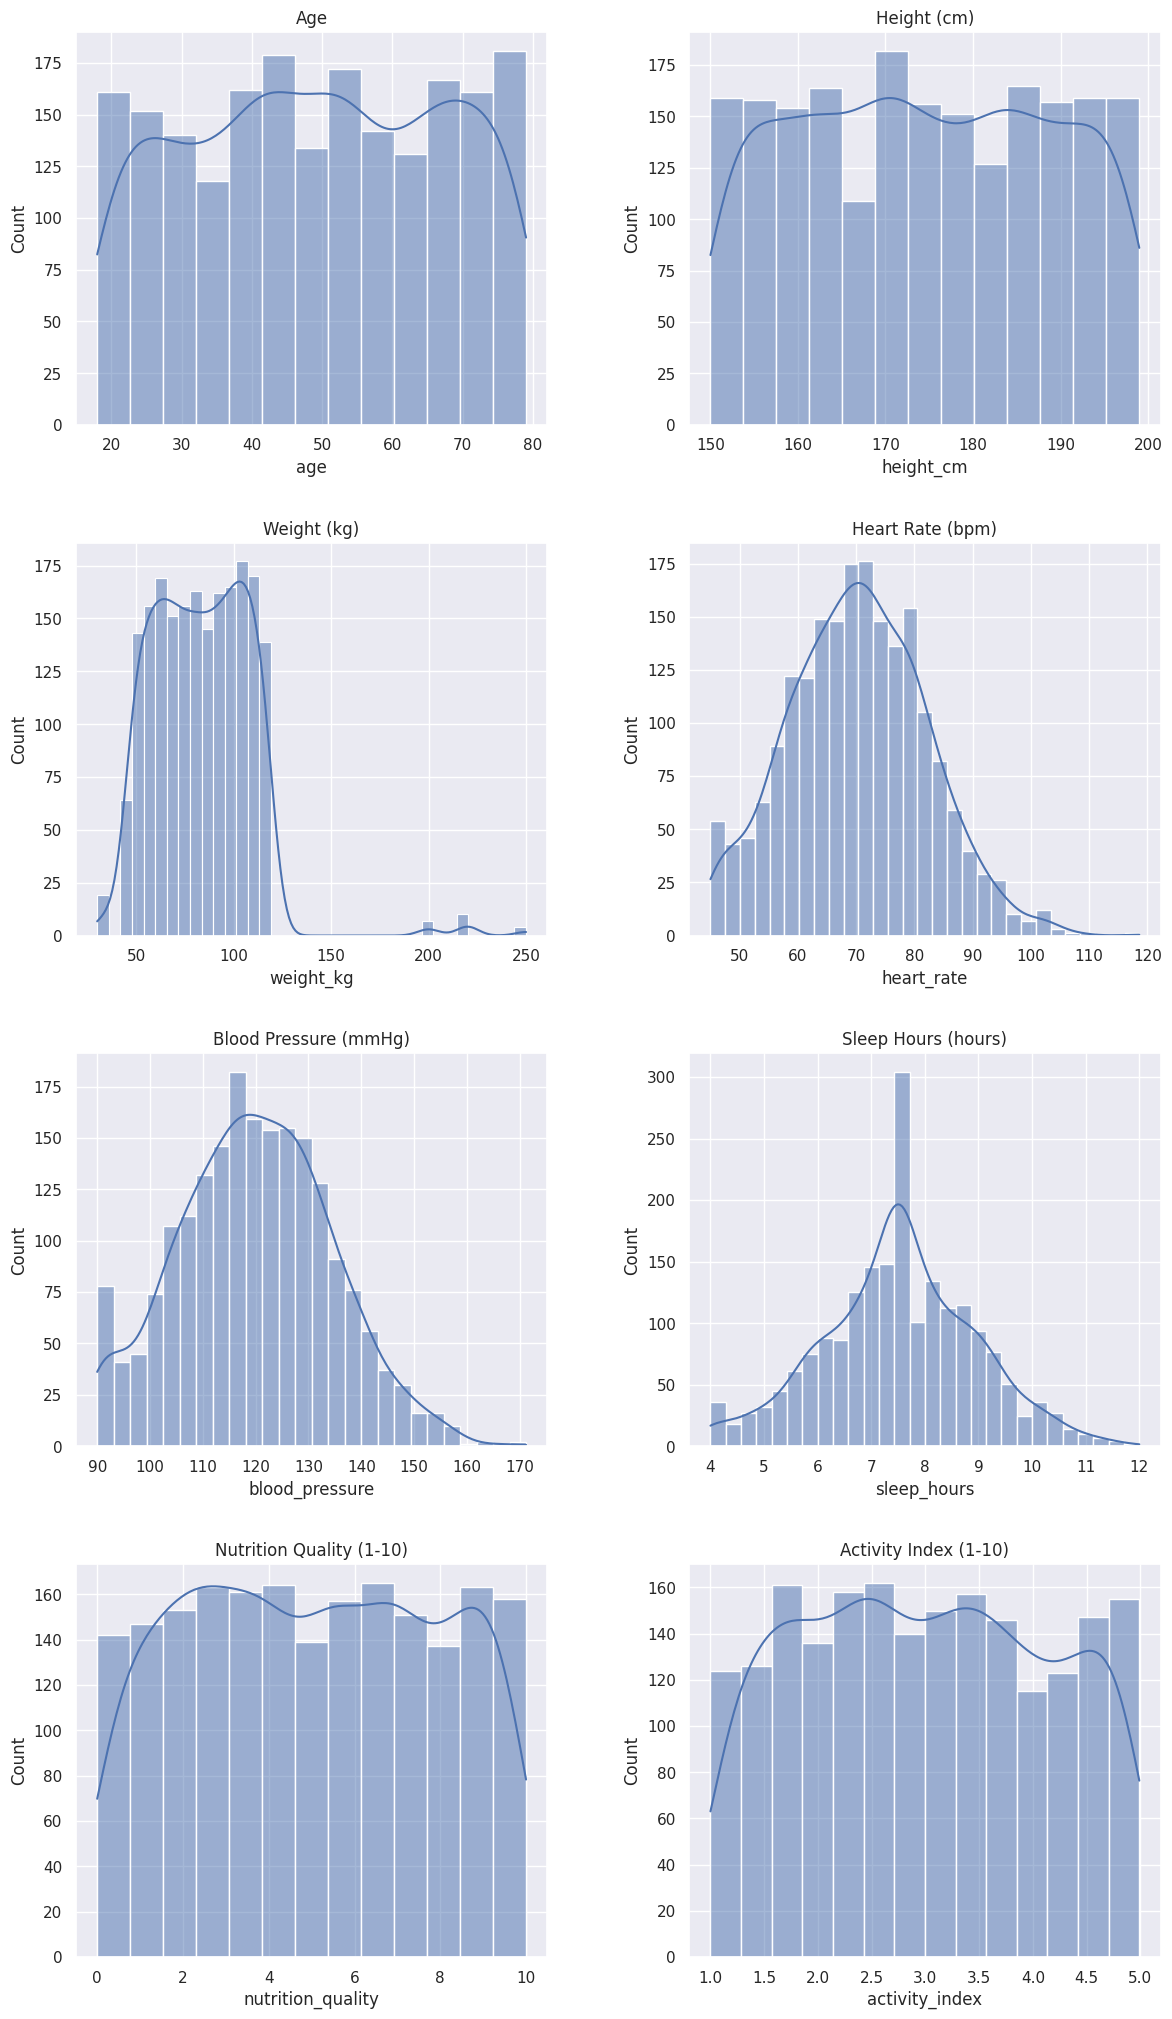

In [ ]:
fig,axes = plt.subplots(4,2,figsize = (14,25))
plt.subplots_adjust(wspace=0.3, hspace=0.3)

sns.histplot(data1['age'], ax= axes[0,0],kde = True)
axes[0,0].set_title('Age')

sns.histplot(data1['height_cm'], ax= axes[0,1],kde = True)
axes[0,1].set_title('Height (cm)')

sns.histplot(data1['weight_kg'], ax= axes[1,0],kde = True)
axes[1,0].set_title('Weight (kg)')

sns.histplot(data1['heart_rate'], ax= axes[1,1],kde = True)
axes[1,1].set_title('Heart Rate (bpm)')

sns.histplot(data1['blood_pressure'], ax= axes[2,0],kde = True)
axes[2,0].set_title('Blood Pressure (mmHg)')

sns.histplot(data1['sleep_hours'], ax= axes[2,1],kde = True)
axes[2,1].set_title('Sleep Hours (hours)')

sns.histplot(data1['nutrition_quality'], ax= axes[3,0],kde = True)
axes[3,0].set_title('Nutrition Quality (1-10)')

sns.histplot(data1['activity_index'], ax= axes[3,1],kde = True)
axes[3,1].set_title('Activity Index (1-10)')

Every data is good but weight. There's an outliers on weight data distribution which is 250kg. But in reality there's a person has 250kg so we keep this data to ensure the model can account for extreme but valid cases.

# Processing The Data

## Declare Dependent and Independent Variable

In [ ]:
x1 = data1.drop('is_fit',axis=1)   #independent variable
y = data1['is_fit']   #dependent variable

## Split Train and Test Data

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( x1, y, test_size=0.2, random_state=42 )

## Build The Regression

We fit a logistic regression model to the data. The model estimates the log-odds of being fit as a linear combination of the predictors.

The regression coefficients show the influence of each variable:
- Positive coefficients increase the likelihood of being fit.
- Negative coefficients decrease the likelihood of being fit.

For example, a negative coefficient for smokes suggests that smoking reduces the chance of being fit.

In [ ]:
x = sm.add_constant(x1)   #add constant to the model (intercept)
log_reg = sm.Logit(y_train, X_train)   #build the model
model_reg = log_reg.fit()   #fit the model
model_reg.summary()

Optimization terminated successfully.
         Current function value: 0.443261
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 is_fit   No. Observations:                 1600
Model:                          Logit   Df Residuals:                     1590
Method:                           MLE   Df Model:                            9
Date:                Sun, 18 Oct 2026   Pseudo R-squ.:                  0.3399
Time:                        03:19:51   Log-Likelihood:                -709.22
converged:                       True   LL-Null:                       -1074.3
Covariance Type:            nonrobust   LLR p-value:                2.172e-151
=====================================================================================
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
age                  -0.0392      0.004    -10.077      0.000      -0.047      -0.032
height_cm             0.0040      0.003      1.213      0.225      -0.002       0.011
weight_kg            -0.0076      0.003     -3.032      0.002      -0.013      -0.003
heart_rate           -0.0069      0.005     -1.309      0.190      -0.017       0.003
blood_pressure       -0.0238      0.004     -5.909      0.000      -0.032      -0.016
sleep_hours           0.2141      0.044      4.842      0.000       0.127       0.301
nutrition_quality     0.2843      0.025     11.204      0.000       0.235       0.334
activity_index        0.9739      0.067     14.573      0.000       0.843       1.105
smokes               -1.9866      0.148    -13.461      0.000      -2.276      -1.697
gender               -1.0293      0.136     -7.591      0.000      -1.295      -0.764
=====================================================================================
"""

## Confusion Matrix
To evaluate predictions, we create a confusion matrix:

- True Positive (TP): Correctly predicted as fit.
- True Negative (TN): Correctly predicted as not fit.
- False Positive (FP): Incorrectly predicted as fit.
- False Negative (FN): Incorrectly predicted as not fit.

This helps us understand model performance beyond accuracy alone.

Therefore, we also compute:

- Precision: Proportion of predicted fit cases that are truly fit.
- Recall: Proportion of actual fit cases that are correctly predicted.
- F1-score: Harmonic mean of precision and recall.

In [ ]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

def confusion_matrix_custom(data, actual_values, model, threshold=0.5):
    # Predict probabilities
    pred_probs = model.predict(data)

    # Convert to binary labels using threshold (classify predicted probabilities of >= 0.5 as class 1 and lower as class 0)
    pred_values = (pred_probs >= threshold).astype(int)

    # Confusion matrix (0 and 1)
    cm = confusion_matrix(actual_values, pred_values, labels=[0,1])

    # Accuracy
    accuracy = np.trace(cm) / cm.sum() * 100

    # Precision, Recall, F1
    precision = precision_score(actual_values, pred_values) * 100
    recall = recall_score(actual_values, pred_values) * 100
    f1 = f1_score(actual_values, pred_values) * 100

    # Print results
    print("Confusion Matrix :\n", cm.astype(int))
    print(f"Accuracy  : {accuracy:.2f} %")
    print(f"Precision : {precision:.2f} %")
    print(f"Recall    : {recall:.2f} %")
    print(f"F1-score  : {f1:.2f} %")

    #return
    return cm, accuracy, precision, recall, f1


# Testing The Model

In [ ]:
print("===## TRAINING RESULT ##===")
cm_train, accuracy_train, precision_train, recall_train, f1_train = (confusion_matrix_custom(X_train, y_train, model_reg))

===## TRAINING RESULT ##===
Confusion Matrix :
 [[824 142]
 [183 451]]
Accuracy  : 79.69 %
Precision : 76.05 %
Recall    : 71.14 %
F1-score  : 73.51 %


In [ ]:
print("===## TEST RESULT ##===")
cm_test, accuracy_test, precision_test, recall_test, f1_test = (confusion_matrix_custom(X_test, y_test, model_reg))

===## TEST RESULT ##===
Confusion Matrix :
 [[196  39]
 [ 55 110]]
Accuracy  : 76.50 %
Precision : 73.83 %
Recall    : 66.67 %
F1-score  : 70.06 %


## Save the model

In [ ]:
# Save the trained model for Streamlit

import pickle

model_bundle = {
    "model": model_reg,
    "feature_names": list(X_train.columns),
    "test_accuracy": accuracy_test,
    "test_precision": precision_test,
    "test_recall": recall_test,
    "test_f1": f1_test
}

with open("fitness_model.pkl", "wb") as file:
    pickle.dump(model_bundle, file)

print("Model saved at:", os.path.abspath("fitness_model.pkl"))

Model saved at: /content/fitness_model.pkl


In [ ]:

from google.colab import files

files.download('/content/fitness_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>